# Actividad 3 (20 %): Modularización del circuito de Grover

**Universidad de Antioquia** · Computación Cuántica · Práctica de Laboratorio No. 3: Algoritmo de Grover  
**Autores:** Carlos Andres Duran Paredes y Juan David Zapata Londoño

Se toma el notebook de la actividad 2 (`Actividad2_N_Grover_2qubits.ipynb`, basado en `N-Grover_AnyMark_2026` del curso) y se organiza
el circuito en **bloques funcionales**, siguiendo el esquema de la Figura 1 del enunciado:

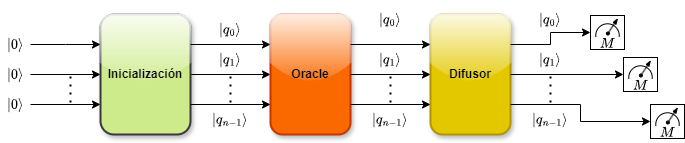

**Figura 1.** Circuito del Algoritmo de Grover dividido en bloques (enunciado de la práctica).

| Parte del algoritmo | Dónde está en el código |
|---|---|
| 1. Inicialización de los qubits | `QuantumCircuit(n, n)`: Qiskit inicia cada qubit en $\lvert 0\rangle$ |
| 2. Compuertas Hadamard | Bloque `Inicializacion(n)`: $H^{\otimes n}\lvert 0\cdots0\rangle = \lvert s\rangle$ |
| 3. Oracle | Bloque `Oracle(MarkState)`: $I - 2\lvert w\rangle\langle w\rvert$ |
| 4. Difusor | Bloque `Difusor(n)`: $H^{\otimes n}(I-2\lvert 0\rangle\langle 0\rvert)H^{\otimes n} = -(2\lvert s\rangle\langle s\rvert - I)$ |
| 5. Operador de Grover | `OperadorGrover(qc, MarkState)`: aplica Oracle y luego Difusor ($G = D\,U_w$) |
| 6. Repetición del operador | Bucle `for` dentro de `Grover(...)`, `num_iteraciones` veces |
| 7. Medición | Bloque `Medicion(n)`: $q_i \to c_i$ |

Convención de Qiskit (*little-endian*): en `MarkState` el dígito de la derecha es $q_0$.
El número de iteraciones se fija aquí a mano (1 para 2 qubits); el cálculo automático es la actividad 4.

In [ ]:
!pip install qiskit qiskit-aer

In [ ]:
!pip install -q pylatexenc

In [3]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, Operator
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
import numpy as np

In [4]:
# Número de qubits
n = 2

# Estado objetivo (MSB → LSB)
MarkState = '01'

# Número de iteraciones de Grover (Oracle + Difusor).
# Para 2 qubits basta UNA iteración (actividad 2).
num_iteraciones = 1

## Bloque 1: Inicialización (Hadamard)

Los qubits empiezan en $\lvert 0\cdots0\rangle$. Una $H$ en cada qubit produce la superposición uniforme
$\lvert s\rangle = \frac{1}{\sqrt{2^n}}\sum_x \lvert x\rangle$: todos los estados con probabilidad $1/2^n$.

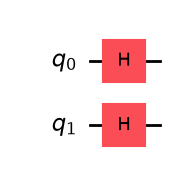

In [5]:
def Inicializacion(n):
    """
    Bloque de inicialización: H en los n qubits -> superposición uniforme |s>.
    (Los qubits ya empiezan en |0...0>, que es el estado inicial de Qiskit.)
    """
    bloque = QuantumCircuit(n, name='Inicialización')
    bloque.h(range(n))
    return bloque

Inicializacion(n).draw('mpl')

## Bloque 2: Oracle

Es la función `Oracle` de la actividad 2, convertida en un bloque que **devuelve su propio circuito**:

1. $X$ en los qubits cuyo dígito es `0`: el estado marcado $\lvert w\rangle$ se convierte en $\lvert 1\cdots1\rangle$.
2. $Z$ multicontrolada ($H\cdot\mathrm{MCX}\cdot H$ sobre el último qubit): cambia el signo solo de $\lvert 1\cdots1\rangle$.
3. Se deshacen las $X$: el signo queda sobre $\lvert w\rangle$.

El bloque acepta también una lista de estados (`['011', '110']`): repite los tres pasos para cada uno, y el resultado es
$I - 2\sum_w \lvert w\rangle\langle w\rvert$. La justificación detallada está en la actividad 6.

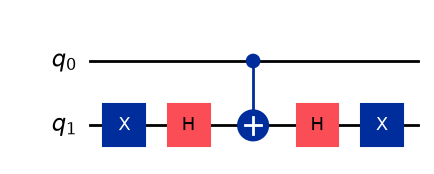

In [6]:
def lista_marcados(MarkState):
    # Acepta un estado ('101') o una lista de estados (['011', '110'])
    return [MarkState] if isinstance(MarkState, str) else list(MarkState)


def Oracle(MarkState):
    """
    Bloque Oracle: marca con fase -1 cada estado de MarkState.
    MarkState: cadena como '1010' (MSB → LSB) o lista de cadenas.
    """
    marcados = lista_marcados(MarkState)
    n = len(marcados[0])
    bloque = QuantumCircuit(n, name='Oracle')

    for w in marcados:
        # Paso 1: aplicar X a los qubits donde el bit = 0 (reversed: el último dígito es q0)
        for i, bit in enumerate(reversed(w)):
            if bit == '0':
                bloque.x(i)

        # Paso 2: Z multicontrolada
        bloque.h(n - 1)
        bloque.mcx(list(range(n - 1)), n - 1)
        bloque.h(n - 1)

        # Paso 3: deshacer el cómputo (uncompute)
        for i, bit in enumerate(reversed(w)):
            if bit == '0':
                bloque.x(i)

    return bloque

Oracle(MarkState).draw('mpl')

## Bloque 3: Difusor

Es la función `diffusion_operator` de la actividad 2 convertida en bloque, con dos cambios:

- Recibe `n` como parámetro, en lugar de leer la variable global `n`.
- No lleva barreras internas: un bloque convertido en compuerta (`to_gate`) solo puede contener operaciones unitarias. Las barreras no cambian el operador.

$X^{\otimes n}\,\mathrm{MCZ}\,X^{\otimes n}$ cambia el signo solo de $\lvert 0\cdots0\rangle$; al rodearlo con $H^{\otimes n}$ queda
$I-2\lvert s\rangle\langle s\rvert = -(2\lvert s\rangle\langle s\rvert - I)$: la inversión sobre la media, con una fase global $-1$ que no afecta la medición.

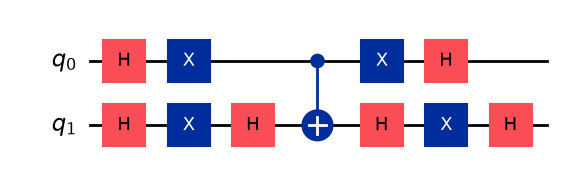

In [7]:
def Difusor(n):
    """
    Bloque Difusor: H^n · (I - 2|0><0|) · H^n = -(2|s><s| - I)
    """
    bloque = QuantumCircuit(n, name='Difusor')

    bloque.h(range(n))
    bloque.x(range(n))
    bloque.h(n - 1)
    bloque.mcx(list(range(n - 1)), n - 1)  # Z multicontrolada
    bloque.h(n - 1)
    bloque.x(range(n))
    bloque.h(range(n))

    return bloque

Difusor(n).draw('mpl')

## Operador de Grover

Una iteración de Grover es el Oracle seguido del Difusor, $G = D\,U_w$. `OperadorGrover` agrega ambos bloques (como compuertas con nombre) al circuito
que recibe. Así el circuito completo conserva las cajas *Oracle* y *Difusor* de la Figura 1.

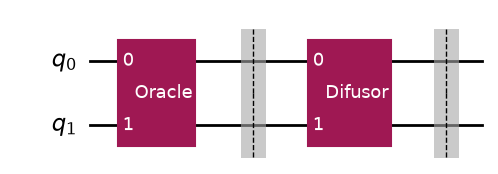

In [8]:
def OperadorGrover(qc, MarkState):
    """
    Aplica una iteración de Grover sobre qc: primero el Oracle y después el Difusor.
    """
    n = qc.num_qubits
    qubits = list(range(n))
    qc.append(Oracle(MarkState).to_gate(label='Oracle'), qubits)
    qc.barrier()
    qc.append(Difusor(n).to_gate(label='Difusor'), qubits)
    qc.barrier()

# Una sola iteración del operador, para verla aislada
G = QuantumCircuit(n)
OperadorGrover(G, MarkState)
G.draw('mpl')

## Bloque 4: Medición

Mide cada qubit $q_i$ en el bit clásico $c_i$, como los medidores $M$ de la Figura 1.

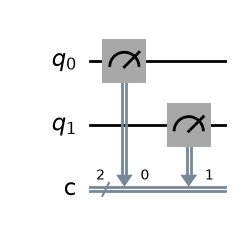

In [9]:
def Medicion(n):
    """
    Bloque de medición: q_i -> c_i
    """
    bloque = QuantumCircuit(n, n, name='Medición')
    bloque.measure(range(n), range(n))
    return bloque

Medicion(n).draw('mpl')

## Ensamblado del circuito de Grover

`Grover` conecta los bloques en el orden de la Figura 1: **Inicialización → (Oracle → Difusor) × `num_iteraciones` → Medición**.

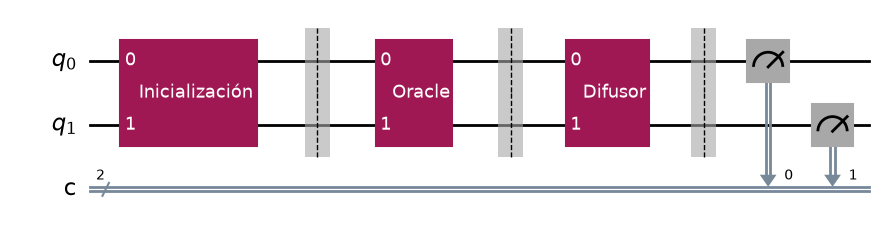

In [10]:
def Grover(n, MarkState, num_iteraciones=1, medir=True):
    """
    Circuito de Grover modular:
    Inicialización -> (Oracle -> Difusor) x num_iteraciones -> Medición
    medir=False deja el circuito sin medición (para el Statevector exacto).
    """
    qubits = list(range(n))
    qc = QuantumCircuit(n, n) if medir else QuantumCircuit(n)   # qubits en |0...0>

    # Bloque 1: Inicialización (Hadamard)
    qc.append(Inicializacion(n).to_gate(label='Inicialización'), qubits)
    qc.barrier()

    # Bloques 2 y 3: operador de Grover, repetido num_iteraciones veces
    for _ in range(num_iteraciones):
        OperadorGrover(qc, MarkState)

    # Bloque 4: Medición
    if medir:
        qc.compose(Medicion(n), qubits=qubits, clbits=qubits, inplace=True)

    return qc

grover_circuit = Grover(n, MarkState, num_iteraciones)
figura = grover_circuit.draw('mpl')
figura.savefig('../figuras/circuito_grover_bloques.png', dpi=150, bbox_inches='tight')
figura

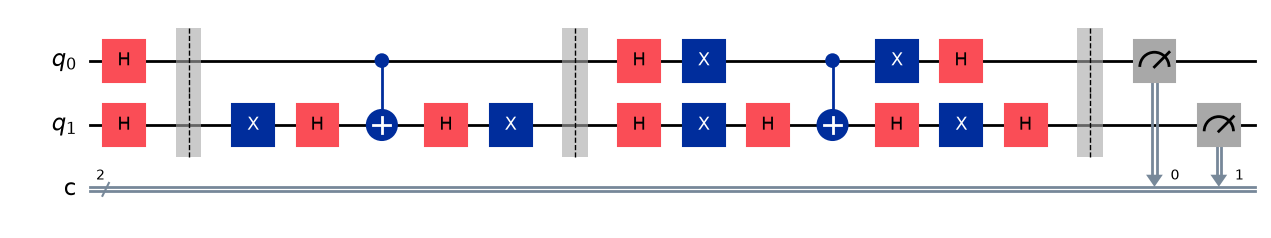

In [11]:
# Contenido de cada bloque (un nivel de descomposición)
grover_circuit.decompose().draw('mpl')

### Contraste con la Figura 1

| Figura 1 | Circuito construido |
|---|---|
| Entradas $\lvert 0\rangle$ en $q_0,\dots,q_{n-1}$ | `QuantumCircuit(n, n)` (todos los qubits en $\lvert 0\rangle$) |
| Caja *Inicialización* | Compuerta `Inicialización` ($H$ en cada qubit) |
| Caja *Oracle* | Compuerta `Oracle` |
| Caja *Difusor* | Compuerta `Difusor` |
| Medidores $M$ | Bloque `Medicion` ($q_i\to c_i$) |

Los tres bloques actúan sobre todos los qubits $q_0,\dots,q_{n-1}$, como en la figura. La figura muestra una sola pasada por Oracle y Difusor;
en el código ese par se repite `num_iteraciones` veces (aquí 1).

## Simulación

### Vector de estado (sin medición)

In [12]:
state = Statevector(Grover(n, MarkState, num_iteraciones, medir=False))
print(state)
state.draw('latex')  # Vista visual de las amplitudes

Statevector([ 2.02038958e-17+0.j, -1.00000000e+00+0.j, -3.92523115e-17+0.j,
             -9.25962153e-17+0.j],
            dims=(2, 2))


<IPython.core.display.Latex object>

El estado final es $-\lvert 01\rangle$, el mismo de la actividad 2: toda la amplitud está en el estado marcado.
El signo $-1$ es la fase global del difusor.

### Muestreo con `AerSimulator`

{'01': 1024}
Probabilidad de éxito P(01) = 1.0


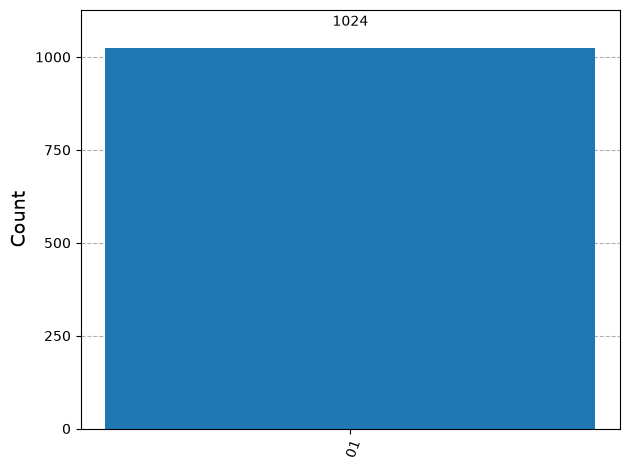

In [13]:
backend = AerSimulator(seed_simulator=2026)   # semilla fija para poder repetir el resultado
qc_transpilado = transpile(grover_circuit, backend)
counts = backend.run(qc_transpilado, shots=1024).result().get_counts()
print(counts)
print('Probabilidad de éxito P(' + MarkState + ') =', counts.get(MarkState, 0) / 1024)
plot_histogram(counts)

## Verificación

### La versión modular es el mismo operador que la versión de la actividad 2

Se reconstruye el circuito de la actividad 2 compuerta por compuerta (sin bloques) y se compara su matriz con la del circuito modular.

In [14]:
# Circuito de la actividad 2, sin bloques: H, oracle de '01' y difusor, una iteración
secuencial = QuantumCircuit(2)
secuencial.h(range(2))
secuencial.x(1); secuencial.h(1); secuencial.cx(0, 1); secuencial.h(1); secuencial.x(1)    # Oracle '01'
secuencial.h(range(2)); secuencial.x(range(2))                                             # Difusor
secuencial.h(1); secuencial.cx(0, 1); secuencial.h(1)
secuencial.x(range(2)); secuencial.h(range(2))

modular = Grover(2, '01', 1, medir=False)
print('¿Mismo operador (incluida la fase global)?',
      np.allclose(Operator(modular).data, Operator(secuencial).data))

¿Mismo operador (incluida la fase global)? True


### Estado al final de cada bloque

Como cada bloque es independiente, se puede simular el circuito hasta el final de cualquiera de ellos.

In [15]:
estado = Statevector.from_label('0' * n)
for nombre, bloque in [('Inicialización', Inicializacion(n)),
                       ('Oracle', Oracle(MarkState)),
                       ('Difusor', Difusor(n))]:
    estado = estado.evolve(bloque)
    print(f'Después de {nombre:15s}', np.round(estado.data.real, 3))

Después de Inicialización  [0.5 0.5 0.5 0.5]
Después de Oracle          [ 0.5 -0.5  0.5  0.5]
Después de Difusor         [ 0. -1. -0. -0.]


### Los mismos bloques sirven para cualquier $n$

Con `n = 3`, `MarkState = '011'` y dos iteraciones (la configuración del notebook original `N-Grover_AnyMark_2026` del curso),
el circuito modular debe reproducir el vector de estado guardado en ese notebook: $0.97227182$ en $\lvert 011\rangle$ y $-0.08838835$ en los demás.

[-0.08838835 -0.08838835 -0.08838835  0.97227182 -0.08838835 -0.08838835
 -0.08838835 -0.08838835]
¿Coincide con el notebook N-Grover_AnyMark_2026? True
P(011) = 0.9453


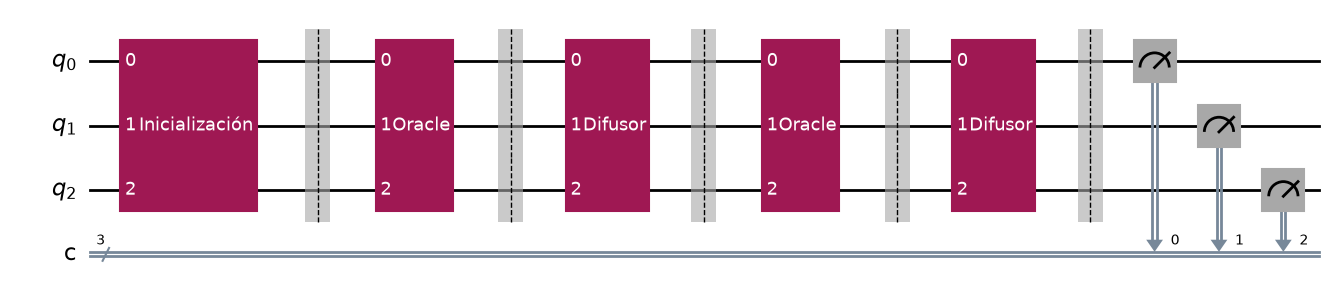

In [16]:
estado_3q = Statevector(Grover(3, '011', 2, medir=False))
esperado = np.full(8, -0.08838835); esperado[int('011', 2)] = 0.97227182   # salida del notebook del curso
print(np.round(estado_3q.data.real, 8))
print('¿Coincide con el notebook N-Grover_AnyMark_2026?', np.allclose(estado_3q.data, esperado, atol=1e-7))
print('P(011) =', round(estado_3q.probabilities()[int('011', 2)], 4))
Grover(3, '011', 2).draw('mpl')

In [17]:
from qiskit import __version__ as qiskit_version
from qiskit_aer import __version__ as aer_version
from platform import python_version

print('Qiskit Version:', qiskit_version)
print('Qiskit_Aer Version:', aer_version)
print('Python Version:', python_version())
print('UdeA-Medellin (2026) ©')

Qiskit Version: 2.5.2
Qiskit_Aer Version: 0.18.2
Python Version: 3.13.14
UdeA-Medellin (2026) ©
